# Student 2 · Traffic Predictor

**Smart Intersection Brain (CS4085 Deep Learning)**: predict traffic speed on the METR-LA road network
5, 15 and 30 minutes ahead. This notebook runs from start to end on Google Colab, Kaggle or locally.

| Part | What it does |
|---|---|
| **A. Get and check the data** | Install PyTorch Geometric Temporal, load METR-LA, count the zero (missing) readings |
| **B. Prepare the data** | Same pipeline as MTGNN / DCRNN: windows, split, normalisation, masked metrics, naive reference |
| **C. LSTM baseline** | One LSTM per sensor history (no graph), masked-MAE training, test results |
| **D. GCN + GRU (T-GCN)** | The brief's graph model on the road graph, trained with MTGNN's recipe; v2 adds DCRNN's diffusion convolution and an encoder–decoder |
| **E. MTGNN** | Re-implementation of the lowest-error reference model |
| **F. Results** | Table vs DCRNN / MTGNN papers, error by horizon, example forecasts |

Parts D and E train for 100 epochs and need a GPU: on Colab, Runtime → Change runtime type → T4 GPU;
on Kaggle, Settings → Accelerator → GPU T4 x2 and Internet on (see the Save the results section at the end).

## A. Get and check the data

### A1. Install

In [1]:
import sys, os
IN_COLAB = "google.colab" in sys.modules
IN_KAGGLE = "KAGGLE_KERNEL_RUN_TYPE" in os.environ       # Kaggle notebook (needs Internet on)
if IN_COLAB or IN_KAGGLE:
    # torch is already installed on Colab and Kaggle
    !pip -q install torch-geometric h5py
    # --no-deps: the package pins torch_sparse/torch_scatter, which need a slow C++ build.
    # The dataset loader and the GCN/GRU layers we use do not need them.
    !pip -q install --no-deps torch-geometric-temporal

In [2]:
import types, warnings
warnings.filterwarnings("ignore", category=FutureWarning)          # torch.jit deprecation noise
warnings.filterwarnings("ignore", message=".*IProgress not found.*")  # tqdm notebook widget notice
# torch_geometric_temporal imports torch_sparse at package level (only EvolveGCN uses it).
# If it is not installed, register an empty stand-in so the package can be imported.
try:
    import torch_sparse  # noqa: F401
except ImportError:
    _stub = types.ModuleType("torch_sparse")
    _stub.SparseTensor = object
    sys.modules["torch_sparse"] = _stub

import os, urllib.request
import numpy as np, pandas as pd, h5py, torch
import matplotlib.pyplot as plt
from torch_geometric_temporal.dataset import METRLADatasetLoader
print("torch", torch.__version__)

torch 2.11.0+cu130


### A2. Download and load METR-LA

`METRLADatasetLoader` downloads `METR-LA.zip` (from Box) into the data folder and loads it.
If Box is unreachable, we fetch the same zip from a GitHub mirror (the original STGCN-PyTorch repo, where this zip comes from).

We also download the original DCRNN file `metr-la.h5`, which carries the **timestamps** and **sensor IDs** (the zip has neither).

In [3]:
# Everything for this part lives in traffic_predictor/ (data/, models/, figures/, results.csv).
# Locally: run from inside that folder or from the repo root.
# On Colab: kept on Google Drive, so the data and the training checkpoints survive a disconnect.
# On Kaggle: /kaggle/working, which becomes the saved output of a "Save Version" run.
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = "/content/drive/MyDrive/SIREN/traffic_predictor"
elif IN_KAGGLE:
    ROOT = "/kaggle/working/traffic_predictor"
else:
    cwd = os.getcwd()
    ROOT = cwd if os.path.basename(cwd) == "traffic_predictor" else (
        os.path.join(cwd, "traffic_predictor") if os.path.isdir(os.path.join(cwd, "traffic_predictor")) else cwd)
DATA_DIR = os.path.join(ROOT, "data", "raw")   # absolute path: the loader breaks on relative paths
os.makedirs(DATA_DIR, exist_ok=True)

MIRRORS = {
    # PyG Temporal zip: adj_mat.npy + node_values.npy
    "METR-LA.zip": "https://raw.githubusercontent.com/FelixOpolka/STGCN-PyTorch/master/data/METR-LA.zip",
    # Original DCRNN data: speeds with timestamps + sensor ids (Git LFS file)
    "metr-la.h5": "https://media.githubusercontent.com/media/kevinkbc/DCRNN_PyTorch/master/data/metr-la.h5",
    # Sensor graph + GPS locations from the official DCRNN repo (used later by the map)
    "adj_mx.pkl": "https://raw.githubusercontent.com/liyaguang/DCRNN/master/data/sensor_graph/adj_mx.pkl",
    "graph_sensor_locations.csv": "https://raw.githubusercontent.com/liyaguang/DCRNN/master/data/sensor_graph/graph_sensor_locations.csv",
}

import hashlib, zipfile, requests

SHA256 = {"metr-la.h5": "64784b76d6fb8ec9bff4b6decafb354da2bb37840468fdccee5044e511277c05"}


def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def is_good(name):
    """A cached file is reused only if it is complete (valid zip / matching checksum)."""
    path = os.path.join(DATA_DIR, name)
    if not os.path.isfile(path):
        return False
    if name.endswith(".zip"):
        return zipfile.is_zipfile(path)
    return name not in SHA256 or sha256(path) == SHA256[name]


def fetch(name):
    """Download to a .part file and rename only when complete, so a dropped connection leaves no bad file."""
    path = os.path.join(DATA_DIR, name)
    urllib.request.urlretrieve(MIRRORS[name], path + ".part")
    os.replace(path + ".part", path)
    if not is_good(name):
        raise RuntimeError(f"{name} failed its integrity check; delete it and rerun")


# A broken zip left by an interrupted earlier run would make the loader fail: remove it first
zip_path = os.path.join(DATA_DIR, "METR-LA.zip")
if os.path.isfile(zip_path) and not is_good("METR-LA.zip"):
    os.remove(zip_path)

try:
    loader = METRLADatasetLoader(raw_data_dir=DATA_DIR)          # official route (Box)
except (requests.RequestException, zipfile.BadZipFile, OSError) as e:
    print(f"Loader download failed ({type(e).__name__}: {e}) -> using GitHub mirror")
    fetch("METR-LA.zip")
    loader = METRLADatasetLoader(raw_data_dir=DATA_DIR)

for name in MIRRORS:
    if not is_good(name):
        fetch(name)
    print(f"{name:28s} {os.path.getsize(os.path.join(DATA_DIR, name))/1e6:7.2f} MB  ok")

100%|██████████| 13.6M/13.6M [00:00<00:00, 112MB/s]


METR-LA.zip                    14.23 MB  ok
metr-la.h5                     57.04 MB  ok
adj_mx.pkl                      0.68 MB  ok
graph_sensor_locations.csv      0.01 MB  ok


In [4]:
print("Loader X (nodes, features, time):", tuple(loader.X.shape))
print("Loader A (adjacency):            ", tuple(loader.A.shape))
print("Edges with weight > 0:", int((loader.A > 0).sum()))

Loader X (nodes, features, time): (207, 2, 34272)
Loader A (adjacency):             (207, 207)
Edges with weight > 0: 1722


The loader returns **z-scored** values (2 features: speed, time-of-day), so a zero reading no longer shows as 0.
To count zeros we use the **raw** speeds in mph: `node_values.npy` (same numbers) or `metr-la.h5` (with timestamps).

In [5]:
with h5py.File(os.path.join(DATA_DIR, "metr-la.h5"), "r") as f:   # old pandas/py2 file: read it with h5py
    sensor_ids = f["df/axis0"][:].astype(str)
    times      = pd.to_datetime(f["df/axis1"][:])
    speed_np   = f["df/block0_values"][:]

speed = pd.DataFrame(speed_np, index=times, columns=sensor_ids)   # (time, sensor), mph

raw = np.load(os.path.join(DATA_DIR, "node_values.npy"))          # (time, sensor, 2)
assert np.allclose(raw[..., 0], speed.values), "h5 and zip disagree"
assert (np.diff(times.values) == np.timedelta64(5, "m")).all(), "time grid has gaps"

print(f"Shape: {speed.shape[0]:,} time steps x {speed.shape[1]} sensors = {speed.size:,} readings")
print(f"From {times[0]} to {times[-1]}, every 5 min (no gaps in the time grid)")
print(f"Speed range: {speed.values.min():.1f} to {speed.values.max():.1f} mph")
speed.iloc[:6, :6]

Shape: 34,272 time steps x 207 sensors = 7,094,304 readings
From 2012-03-01 00:00:00 to 2012-06-27 23:55:00, every 5 min (no gaps in the time grid)
Speed range: 0.0 to 70.0 mph


,773869,767541,767542,717447,717446,717445
2012-03-01 00:00:00,64.375000,67.625000,67.125000,61.500000,66.875000,68.750000
2012-03-01 00:05:00,62.666667,68.555556,65.444444,62.444444,64.444444,68.111111
2012-03-01 00:10:00,64.000000,63.750000,60.000000,59.000000,66.500000,66.250000
2012-03-01 00:15:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2012-03-01 00:20:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2012-03-01 00:25:00,57.333333,69.000000,67.666667,61.666667,67.333333,69.000000


### A3. Count the zeros (= missing readings)

In [6]:
missing = (speed == 0)                      # True where the sensor sent nothing
n_zero, n_all = int(missing.values.sum()), missing.size
print(f"Zero readings: {n_zero:,} of {n_all:,}  ->  {n_zero/n_all:.2%} missing")

per_sensor = missing.mean().sort_values(ascending=False)
per_step   = missing.sum(axis=1)
print(f"Sensors with no zeros at all : {(per_sensor == 0).sum()}")
print(f"Sensors with  >10% zeros     : {(per_sensor > 0.10).sum()}")
print(f"Sensors with  >50% zeros     : {(per_sensor > 0.50).sum()}")
print(f"Time steps where ALL 207 sensors are zero: {(per_step == speed.shape[1]).sum():,} "
      f"({(per_step == speed.shape[1]).mean():.2%} of time steps)")
print(f"Time steps with at least one zero:         {(per_step > 0).sum():,}")
from_outages = missing[per_step == speed.shape[1]].values.sum()
print(f"Zeros that come from those network-wide outages: {from_outages:,} ({from_outages/n_zero:.0%} of all zeros)")
print("\nWorst 10 sensors (share of readings missing):")
print(per_sensor.head(10).map("{:.1%}".format).to_string())

Zero readings: 575,302 of 7,094,304  ->  8.11% missing
Sensors with no zeros at all : 0
Sensors with  >10% zeros     : 34
Sensors with  >50% zeros     : 0
Time steps where ALL 207 sensors are zero: 2,148 (6.27% of time steps)
Time steps with at least one zero:         29,066
Zeros that come from those network-wide outages: 444,636 (77% of all zeros)

Worst 10 sensors (share of readings missing):
718076    20.1%
716939    18.9%
760987    16.1%
716955    15.7%
769418    15.6%
769405    15.6%
717481    15.1%
717510    15.0%
717513    14.1%
717576    13.6%


#### Why zero means *missing*, not *stopped traffic*

If zeros were real jams we would expect speeds to slide smoothly down to 0. Instead there is a jump:
almost no readings between 0 and a few mph, and zeros often hit **all sensors at the same moment** (a data-collection outage).

In [7]:
v = speed.values
nonzero = v[v > 0]
print(f"Readings exactly 0         : {n_zero:,}")
print(f"Readings in (0, 5) mph     : {((v > 0) & (v < 5)).sum():,}")
print(f"Readings in [5, 10) mph    : {((v >= 5) & (v < 10)).sum():,}")
print(f"Smallest non-zero speed    : {nonzero.min():.2f} mph")

# Length of each run of consecutive zeros, per sensor
runs = []
for col in missing.columns:
    m = missing[col].values.astype(np.int8)
    edges = np.flatnonzero(np.diff(np.r_[0, m, 0]))
    runs.extend(edges[1::2] - edges[::2])
runs = np.array(runs)
print(f"\nRuns of consecutive zeros: {len(runs):,}; median {np.median(runs):.0f} steps "
      f"({np.median(runs)*5:.0f} min), longest {runs.max():,} steps ({runs.max()*5/60/24:.1f} days)")

Readings exactly 0         : 575,302
Readings in (0, 5) mph     : 3,378
Readings in [5, 10) mph    : 26,431
Smallest non-zero speed    : 0.33 mph

Runs of consecutive zeros: 25,963; median 2 steps (10 min), longest 1,683 steps (5.8 days)


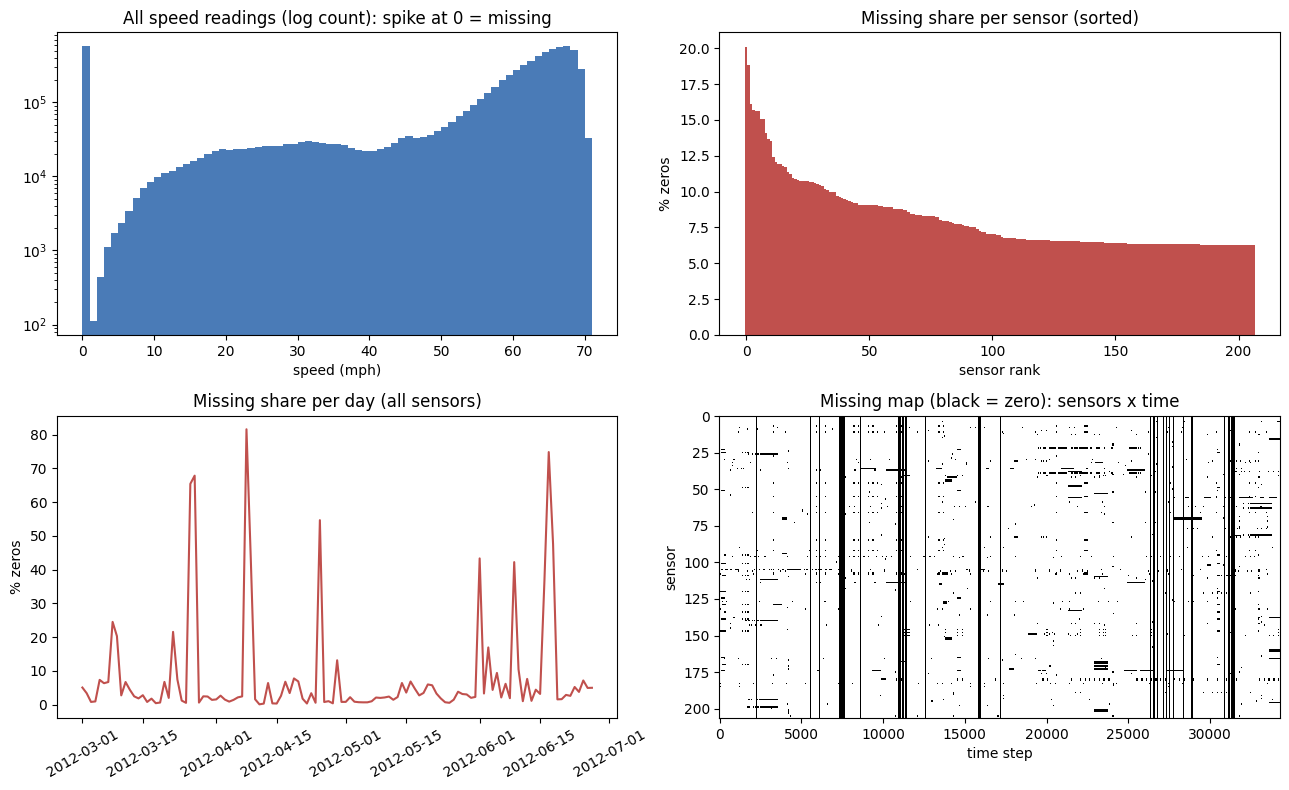

In [8]:
fig, ax = plt.subplots(2, 2, figsize=(13, 8))

ax[0, 0].hist(v.ravel(), bins=71, range=(0, 71), color="#4a7bb7")
ax[0, 0].set_yscale("log"); ax[0, 0].set_title("All speed readings (log count): spike at 0 = missing")
ax[0, 0].set_xlabel("speed (mph)")

ax[0, 1].bar(range(len(per_sensor)), per_sensor.values * 100, color="#c0504d", width=1)
ax[0, 1].set_title("Missing share per sensor (sorted)"); ax[0, 1].set_ylabel("% zeros")
ax[0, 1].set_xlabel("sensor rank")

daily = missing.mean(axis=1).resample("D").mean() * 100
ax[1, 0].plot(daily.index, daily.values, color="#c0504d")
ax[1, 0].set_title("Missing share per day (all sensors)"); ax[1, 0].set_ylabel("% zeros")
ax[1, 0].tick_params(axis="x", labelrotation=30)

ax[1, 1].imshow(missing.values.T, aspect="auto", interpolation="nearest", cmap="Greys")
ax[1, 1].set_title("Missing map (black = zero): sensors x time")
ax[1, 1].set_xlabel("time step"); ax[1, 1].set_ylabel("sensor")
plt.tight_layout()
os.makedirs(os.path.join(ROOT, "figures"), exist_ok=True)
plt.savefig(os.path.join(ROOT, "figures", "metr_la_missing.png"), dpi=120)
plt.show()

#### What the zeros do to the PyG loader's output

The loader z-scores with the zeros **included**, so every missing reading becomes the same constant `-mean/std`
and the mean itself is pulled down. A model trained on that would learn to predict fake "0 mph" drops.

In [9]:
spd = raw[..., 0].astype(np.float32)
mean_all, std_all = spd.mean(), spd.std()
mean_ok,  std_ok  = spd[spd > 0].mean(), spd[spd > 0].std()
print(f"Mean / std with zeros   : {mean_all:.2f} / {std_all:.2f} mph   (what the loader uses)")
print(f"Mean / std without zeros: {mean_ok:.2f} / {std_ok:.2f} mph")
z0 = (0 - mean_all) / std_all
x_at_missing = loader.X[:, 0, :].numpy().T[missing.values]      # loader values where raw speed is 0
print(f"Expected value of a missing reading in loader.X: {z0:.3f}")
print(f"Actual values there: min {x_at_missing.min():.3f}, max {x_at_missing.max():.3f} "
      f"({len(x_at_missing):,} readings, all the same constant)")

Mean / std with zeros   : 53.72 / 20.26 mph   (what the loader uses)
Mean / std without zeros: 58.46 / 13.02 mph
Expected value of a missing reading in loader.X: -2.651
Actual values there: min -2.652, max -2.652 (575,302 readings, all the same constant)


### A4. Takeaways for part B

- **8.1%** of METR-LA readings (575,302 of 7.09 M) are 0 = missing. About three quarters of them come from network-wide outages where all 207 sensors are 0 at once; the rest are single sensors dropping out (worst sensor: 20% missing). Every sensor has some zeros.
- Zeros are not real speeds, so they must never count as errors. Part B follows MTGNN / DCRNN: zeros stay in the inputs, and the loss and scores use a **masked MAE / RMSE** that ignores targets equal to 0.
- Normalisation mean/std come from the **training split only** (zeros included, as in DCRNN).
- Use the DCRNN split: first 70% train, next 10% validation, last 20% test (in time order).
- For the app: avoid placing the ambulance at a sensor with many missing readings.

In [10]:
# Save the mask and per-sensor missing table for later notebooks / the app
OUT = os.path.join(ROOT, "data", "processed"); os.makedirs(OUT, exist_ok=True)
np.save(os.path.join(OUT, "metr_la_missing_mask.npy"), missing.values)
per_sensor.rename("missing_share").to_csv(os.path.join(OUT, "metr_la_missing_per_sensor.csv"), header=True)
print("saved data/processed/metr_la_missing_mask.npy and metr_la_missing_per_sensor.csv")

saved data/processed/metr_la_missing_mask.npy and metr_la_missing_per_sensor.csv


## B. Prepare the data like the strongest model

We copy the data pipeline of **MTGNN** (Wu et al., KDD 2020), the strongest of the reference models
at our horizons. MTGNN reuses DCRNN's data script, so the numbers stay comparable with DCRNN.

MTGNN's reported METR-LA results: **MAE 2.69 at 15 min, 3.05 at 30 min**
(RMSE 5.18 and 6.17). DCRNN reports 2.77 and 3.15.

| Choice | What MTGNN / DCRNN do | Where in their code |
|---|---|---|
| Zeros (missing) in inputs | **Kept as 0**, no imputation | `generate_training_data.py` |
| Features | speed + time of day | `add_time_in_day=True` |
| Window | 12 steps in (1 h) → 12 steps out | `x_offsets=-11..0`, `y_offsets=1..12` |
| Split | windows in time order, 70 / 10 / 20 | `round(n*0.7)`, `round(n*0.2)` |
| Normalisation | z-score speed of **train inputs**, zeros included; targets stay in mph | `util.load_dataset` |
| Loss | **masked MAE**: targets equal to 0 are ignored | `trainer.py`: `masked_mae(predict, real, 0.0)` |
| Metrics | masked MAE / RMSE / MAPE per horizon | `util.metric` |

### B1. Features, windows and split

In [11]:
from torch.utils.data import Dataset, DataLoader

SEQ_IN, SEQ_OUT = 12, 12                  # 1 hour in -> 1 hour out
TRAIN_RATIO, TEST_RATIO = 0.7, 0.2
HORIZONS = {"5 min": 0, "15 min": 2, "30 min": 5}   # index in the 12-step output


def build_features(speed):
    """(T, N, 2) float32: [speed mph, time of day 0..1), as DCRNN add_time_in_day=True."""
    idx = speed.index.values
    tod = (idx - idx.astype("datetime64[D]")) / np.timedelta64(1, "D")
    tod = np.tile(tod[:, None], (1, speed.shape[1]))
    return np.stack([speed.values, tod], axis=-1).astype(np.float32)


def split_starts(num_steps):
    """Index t of the last input step of every window, split like DCRNN (by window, in time order)."""
    t = np.arange(SEQ_IN - 1, num_steps - SEQ_OUT)
    n = len(t)
    n_test, n_train = round(n * TEST_RATIO), round(n * TRAIN_RATIO)
    n_val = n - n_test - n_train
    return {"train": t[:n_train], "val": t[n_train:n_train + n_val], "test": t[-n_test:]}


data = build_features(speed)              # `speed` is the (time, sensor) DataFrame from part A
starts = split_starts(len(data))

pd.DataFrame([{"split": k, "windows": len(t),
               "first input": times[t[0] - SEQ_IN + 1], "last target": times[t[-1] + SEQ_OUT]}
              for k, t in starts.items()]).set_index("split")

,windows,first input,last target
split,,,
train,23974,2012-03-01 00:00:00,2012-05-23 07:40:00
val,3425,2012-05-23 05:50:00,2012-06-04 05:05:00
test,6850,2012-06-04 03:15:00,2012-06-27 23:55:00


DCRNN's published `train.npz / val.npz / test.npz` have 23,974 / 3,425 / 6,850 samples. We get the same.
We slice the windows on the fly instead of saving those files, which are about 2.7 GB.

### B2. Normalisation and dataset

In [12]:
assert [len(v) for v in starts.values()] == [23974, 3425, 6850]


class StandardScaler:
    def __init__(self, mean, std):
        self.mean, self.std = float(mean), float(std)

    @classmethod
    def fit_train_inputs(cls, data, train_t):
        """Mean/std of the speed in every train INPUT window, zeros included (DCRNN/MTGNN)."""
        rows = train_t[:, None] + np.arange(-SEQ_IN + 1, 1)[None, :]
        x = data[rows, :, 0].astype(np.float64)
        return cls(x.mean(), x.std())

    def transform(self, x):
        return (x - self.mean) / self.std

    def inverse_transform(self, x):
        return x * self.std + self.mean


class WindowDataset(Dataset):
    """x: (12, N, 2) with z-scored speed; y: (12, N) speed in mph (0 = missing)."""

    def __init__(self, data, starts, scaler):
        x = data.copy()
        x[..., 0] = scaler.transform(x[..., 0])
        self.x, self.y = torch.from_numpy(x), torch.from_numpy(data[..., 0].copy())
        self.starts = starts

    def __len__(self):
        return len(self.starts)

    def __getitem__(self, i):
        t = int(self.starts[i])
        return self.x[t - SEQ_IN + 1:t + 1], self.y[t + 1:t + 1 + SEQ_OUT]


scaler = StandardScaler.fit_train_inputs(data, starts["train"])
print(f"Scaler from train inputs (zeros included): mean {scaler.mean:.3f}, std {scaler.std:.3f} mph")

ds = {k: WindowDataset(data, v, scaler) for k, v in starts.items()}
x, y = ds["train"][0]
print("one sample  x:", tuple(x.shape), "(12 steps, 207 sensors, [z-speed, time of day])")
print("            y:", tuple(y.shape), "(12 future steps, 207 sensors, mph)")

Scaler from train inputs (zeros included): mean 54.406, std 19.494 mph
one sample  x: (12, 207, 2) (12 steps, 207 sensors, [z-speed, time of day])
            y: (12, 207) (12 future steps, 207 sensors, mph)


### B3. Masked metrics

Copied from DCRNN / Graph WaveNet / MTGNN: targets equal to 0 are ignored, and the mask is rescaled
so the score is the average over real readings only.

In [13]:
NULL_VAL = 0.0


def _mask(labels, null_val=NULL_VAL):
    mask = (labels != null_val).float()
    return torch.nan_to_num(mask / torch.mean(mask))


def masked_mae(preds, labels, null_val=NULL_VAL):
    return torch.mean(torch.nan_to_num(torch.abs(preds - labels) * _mask(labels, null_val)))


def masked_rmse(preds, labels, null_val=NULL_VAL):
    return torch.sqrt(torch.mean(torch.nan_to_num((preds - labels) ** 2 * _mask(labels, null_val))))


def masked_mape(preds, labels, null_val=NULL_VAL):
    loss = torch.abs(preds - labels) / labels * _mask(labels, null_val)
    return torch.mean(torch.nan_to_num(loss, posinf=0.0))


def horizon_report(preds, labels):
    """Masked MAE / RMSE / MAPE at 5, 15, 30 min. preds, labels: (samples, 12, N) in mph."""
    rows = {}
    for name, h in HORIZONS.items():
        p, y = preds[:, h], labels[:, h]
        rows[name] = {"MAE": masked_mae(p, y).item(), "RMSE": masked_rmse(p, y).item(),
                      "MAPE %": 100 * masked_mape(p, y).item()}
    return pd.DataFrame(rows).T.round(3)


# quick check: the two zero targets are ignored -> mean of |58-60| and |47-50| = 2.5
_y = torch.tensor([[0., 60.], [50., 0.]]); _p = torch.tensor([[10., 58.], [47., 30.]])
assert abs(masked_mae(_p, _y).item() - 2.5) < 1e-6

def target_rows(t):
    return t[:, None] + np.arange(1, SEQ_OUT + 1)[None, :]

for k, t in starts.items():
    print(f"{k:5s}: {(data[target_rows(t), :, 0] == 0).mean():.2%} of target readings are 0 -> ignored")

train: 7.13% of target readings are 0 -> ignored
val  : 6.97% of target readings are 0 -> ignored
test : 12.11% of target readings are 0 -> ignored


The test split has more missing targets than train, so without the mask the scores would not be
comparable with the papers.

### B4. Naive reference forecast

Before training anything, score a forecast that just **repeats the last real reading** (skipping zeros).
Any model we train must beat this. It also shows why masking matters.

In [14]:
ffill = speed.replace(0, np.nan).ffill().fillna(0).values.astype(np.float32)   # last real reading

t = starts["test"]
p_naive = torch.from_numpy(np.repeat(ffill[t][:, None, :], SEQ_OUT, axis=1))   # (n, 12, N)
yt = torch.from_numpy(data[target_rows(t), :, 0])
naive = horizon_report(p_naive, yt)
print("Naive 'repeat last reading' on the TEST split (masked metrics):")
display(naive)

unmasked = {h: round(torch.mean(torch.abs(p_naive[:, i] - yt[:, i])).item(), 2) for h, i in HORIZONS.items()}
print("Same forecast scored WITHOUT the mask (MAE):", unmasked)
print("-> without the mask the zeros add large fake errors, so scores can't be compared with the papers.")

Naive 'repeat last reading' on the TEST split (masked metrics):


,MAE,RMSE,MAPE %
5 min,2.814,4.626,6.487
15 min,3.498,6.416,8.608
30 min,4.205,8.049,10.852


Same forecast scored WITHOUT the mask (MAE): {'5 min': 9.55, '15 min': 10.15, '30 min': 10.76}
-> without the mask the zeros add large fake errors, so scores can't be compared with the papers.


### B5. Data loaders for the models

In [15]:
loaders = {
    "train": DataLoader(ds["train"], batch_size=64, shuffle=True),
    "val":   DataLoader(ds["val"],   batch_size=64),
    "test":  DataLoader(ds["test"],  batch_size=64),
}
xb, yb = next(iter(loaders["train"]))
print("batch x:", tuple(xb.shape), " batch y:", tuple(yb.shape))

# Training step every model will use (as in MTGNN's trainer):
#   pred_mph = scaler.inverse_transform(model(xb))      # model outputs z-scores
#   loss = masked_mae(pred_mph, yb)                      # ignore targets == 0
#   loss.backward(); clip_grad_norm_(params, 5); optimizer.step()

batch x: (64, 12, 207, 2)  batch y: (64, 12, 207)


## C. LSTM baseline (time only)

The brief's baseline: an LSTM that uses **only the time history of each sensor**. It never sees the road graph.
One LSTM is shared by all 207 sensors: each sensor's last 12 steps of [speed, time of day] go in,
and its next 12 speeds come out at once.

Training follows MTGNN's trainer: the model outputs z-scores, we convert them back to mph and minimise the
**masked MAE**; Adam, gradient clipping at 5, early stopping on the validation masked MAE.

Reference from the DCRNN paper (Table 2, METR-LA): **FC-LSTM MAE 3.44 at 15 min, 3.77 at 30 min**
(RMSE 6.30 / 7.23). Their FC-LSTM reads all 207 sensors as one vector; ours treats each sensor on its own,
which is the "time only" baseline the brief asks for.

### C1. Training tools (shared with parts D and E)

Training saves a checkpoint after every epoch, so a disconnect only loses the current epoch: rerun the
notebook and it resumes (on Colab the checkpoints are on Google Drive). When a model has finished training,
rerunning just loads it, and models already trained and pushed to GitHub are downloaded instead of retrained.
Delete `models/<name>_checkpoint.pt` to train again from scratch.

`fit` covers both recipes: the LSTM uses early stopping; parts D and E use MTGNN's recipe
(weight decay, 100 epochs, curriculum learning).

In [16]:
import time, json, glob, shutil
import torch.nn as nn
import torch.nn.functional as F

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MODEL_DIR = os.path.join(ROOT, "models"); os.makedirs(MODEL_DIR, exist_ok=True)
QUICK_CHECK = False        # True: 2 short epochs only, to test the code; results are not meaningful
REPO_MODELS = "https://raw.githubusercontent.com/AhmadBaabod/SIREN/main/traffic_predictor/models/"
torch.manual_seed(0); np.random.seed(0)
print("device:", DEVICE)


def predict(model, loader):
    """Predictions and targets in mph, shape (samples, 12, N)."""
    model.eval()
    preds, ys = [], []
    with torch.no_grad():
        for xb, yb in loader:
            preds.append(scaler.inverse_transform(model(xb.to(DEVICE))).cpu())
            ys.append(yb)
    return torch.cat(preds), torch.cat(ys)


def fetch_trained(name):
    """Get a model's saved weights if they are not here yet: on Kaggle from an earlier run of this
    notebook added as input, otherwise from the GitHub repo."""
    files = [f"{name}_checkpoint.pt", f"{name}.pt"]
    paths = [os.path.join(MODEL_DIR, f) for f in files]
    if QUICK_CHECK or any(os.path.isfile(p) for p in paths):
        return
    if IN_KAGGLE:           # Add Input -> Your Work -> this notebook: its last output is under /kaggle/input
        found = [glob.glob(f"/kaggle/input/**/models/{f}", recursive=True) for f in files]
        if found[0]:
            for hits, p in zip(found, paths):
                if hits:
                    shutil.copy(hits[0], p)
            print(f"copied {name} from the earlier Kaggle run: {os.path.dirname(found[0][0])}")
            return
    try:
        for f, p in zip(files, paths):
            urllib.request.urlretrieve(REPO_MODELS + f, p + ".part")
            os.replace(p + ".part", p)
        print(f"downloaded the trained {name} from GitHub")
    except OSError:                       # not pushed yet: fit() trains it
        for p in paths:
            for q in (p, p + ".part"):
                if os.path.isfile(q):
                    os.remove(q)


def save_atomic(obj, path):
    """Write to a .part file, then rename: a disconnect during the save never leaves a broken file."""
    torch.save(obj, path + ".part")
    os.replace(path + ".part", path)


def fit(model, name, max_epochs=30, lr=1e-3, patience=5, clip=5.0, weight_decay=0.0, cl_step=None):
    """Train with masked MAE and keep the weights with the best validation MAE; resume from a checkpoint.

    patience=None: no early stopping, train all max_epochs (MTGNN).
    cl_step: MTGNN's curriculum learning. The loss starts with the 5-minute step only and adds the next
    future step every cl_step batches, so the model learns short horizons before long ones.
    """
    if QUICK_CHECK:
        name, max_epochs = name + "_quick", 2
    fetch_trained(name)
    model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    ckpt, best_path = (os.path.join(MODEL_DIR, f"{name}{s}.pt") for s in ("_checkpoint", ""))
    state = {"epoch": 0, "best_val": float("inf"), "bad_epochs": 0, "history": []}
    best_weights = None
    if os.path.isfile(ckpt):
        saved = torch.load(ckpt, map_location=DEVICE)
        model.load_state_dict(saved["model"]); opt.load_state_dict(saved["opt"]); state = saved["state"]
        best_weights = saved.get("best")          # older checkpoints (the LSTM) do not store it
        if best_weights is not None:              # the checkpoint is the record: redo a best save cut short
            save_atomic(best_weights, best_path)
        print(f"loaded {name} checkpoint after epoch {state['epoch']}; earlier epochs:")
        best = float("inf")
        for h in state["history"]:
            mark = "  *best" if h["val_mae"] < best else ""
            best = min(best, h["val_mae"])
            print(f"epoch {h['epoch']:3d}  train MAE {h['train_mae']:.3f}  val MAE {h['val_mae']:.3f}  "
                  f"({h['seconds']:.0f}s){mark}")
    state.setdefault("iter", 1); state.setdefault("task_level", 1)      # curriculum position
    patience = float("inf") if patience is None else patience

    while state["epoch"] < max_epochs and state["bad_epochs"] < patience:
        model.train()
        t0, losses = time.time(), []
        for i, (xb, yb) in enumerate(loaders["train"]):
            if QUICK_CHECK and i == 20:
                break
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            steps = SEQ_OUT
            if cl_step:                   # same rule as MTGNN's trainer.py
                if state["iter"] % cl_step == 0 and state["task_level"] <= SEQ_OUT:
                    state["task_level"] += 1
                steps = state["task_level"]
            pred = scaler.inverse_transform(model(xb))
            loss = masked_mae(pred[:, :steps], yb[:, :steps])
            opt.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), clip)
            opt.step()
            losses.append(loss.item())
            state["iter"] += 1
        val = masked_mae(*predict(model, loaders["val"])).item()
        state["epoch"] += 1
        state["history"].append({"epoch": state["epoch"], "train_mae": float(np.mean(losses)),
                                 "val_mae": val, "seconds": time.time() - t0})
        if val < state["best_val"]:
            state["best_val"], state["bad_epochs"] = val, 0
            best_weights = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            state["bad_epochs"] += 1
        cl_note = f"  loss on {min(state['task_level'], SEQ_OUT)} steps" if cl_step else ""
        print(f"epoch {state['epoch']:3d}  train MAE {np.mean(losses):.3f}  val MAE {val:.3f}  "
              f"({time.time() - t0:.0f}s){cl_note}{'  *best' if state['bad_epochs'] == 0 else ''}")
        # checkpoint first (it also holds the best weights), then the best-weights file
        save_atomic({"model": model.state_dict(), "opt": opt.state_dict(), "state": state,
                     "best": best_weights}, ckpt)
        if state["bad_epochs"] == 0:
            save_atomic(best_weights, best_path)

    model.load_state_dict(torch.load(best_path, map_location=DEVICE))
    print(f"{name}: {state['epoch']} epochs, best val MAE {state['best_val']:.3f}")
    return pd.DataFrame(state["history"]).set_index("epoch")


def plot_history(history, title, curriculum=False):
    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.plot(history.index, history["train_mae"], label="train (curriculum steps only)" if curriculum else "train")
    ax.plot(history.index, history["val_mae"], label="validation (all 12 steps)")
    ax.set_xlabel("epoch"); ax.set_ylabel("masked MAE (mph)"); ax.set_title(title); ax.legend()
    plt.tight_layout(); plt.show()


# MTGNN's METR-LA settings (train.py defaults), used for parts D and E
MTGNN_RECIPE = dict(max_epochs=100, lr=1e-3, weight_decay=1e-4, clip=5.0, patience=None, cl_step=2500)

results = {"Naive: repeat last reading": naive}     # test-set tables of every model we evaluate

device: cuda


### C2. Model

In [17]:
class LSTMBaseline(nn.Module):
    """One LSTM shared by all sensors; each sensor sees only its own past (no road graph)."""

    def __init__(self, in_dim=2, hidden=64, layers=2, horizon=SEQ_OUT):
        super().__init__()
        self.lstm = nn.LSTM(in_dim, hidden, layers, batch_first=True)
        self.head = nn.Linear(hidden, horizon)

    def forward(self, x):                                  # x: (B, 12, N, 2)
        B, T, N, F = x.shape
        seq = x.permute(0, 2, 1, 3).reshape(B * N, T, F)   # every sensor becomes its own sequence
        out, _ = self.lstm(seq)
        y = self.head(out[:, -1])                          # (B*N, 12) z-scores, all horizons at once
        return y.reshape(B, N, -1).permute(0, 2, 1)        # (B, 12, N)


lstm = LSTMBaseline()
print(f"LSTM parameters: {sum(p.numel() for p in lstm.parameters()):,}")

LSTM parameters: 51,468


### C3. Train

downloaded the trained lstm from GitHub
loaded lstm checkpoint after epoch 30; earlier epochs:
epoch   1  train MAE 4.829  val MAE 3.961  (229s)  *best
epoch   2  train MAE 3.927  val MAE 3.677  (227s)  *best
epoch   3  train MAE 3.758  val MAE 3.572  (215s)  *best
epoch   4  train MAE 3.717  val MAE 3.714  (217s)
epoch   5  train MAE 3.689  val MAE 3.510  (211s)  *best
epoch   6  train MAE 3.664  val MAE 3.480  (227s)  *best
epoch   7  train MAE 3.646  val MAE 3.484  (229s)
epoch   8  train MAE 3.628  val MAE 3.448  (220s)  *best
epoch   9  train MAE 3.608  val MAE 3.435  (206s)  *best
epoch  10  train MAE 3.590  val MAE 3.402  (211s)  *best
epoch  11  train MAE 3.563  val MAE 3.380  (211s)  *best
epoch  12  train MAE 3.542  val MAE 3.379  (210s)  *best
epoch  13  train MAE 3.522  val MAE 3.354  (202s)  *best
epoch  14  train MAE 3.509  val MAE 3.361  (206s)
epoch  15  train MAE 3.496  val MAE 3.333  (207s)  *best
epoch  16  train MAE 3.489  val MAE 3.358  (215s)
epoch  17  train MAE 

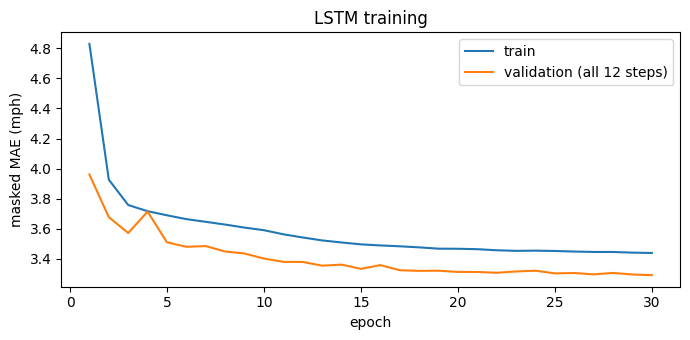

In [18]:
lstm_history = fit(lstm, "lstm")
plot_history(lstm_history, "LSTM training")

### C4. Test results

,MAE,RMSE,MAPE %
5 min,2.40,4.239,5.966
15 min,3.01,5.898,8.052
30 min,3.62,7.257,10.376


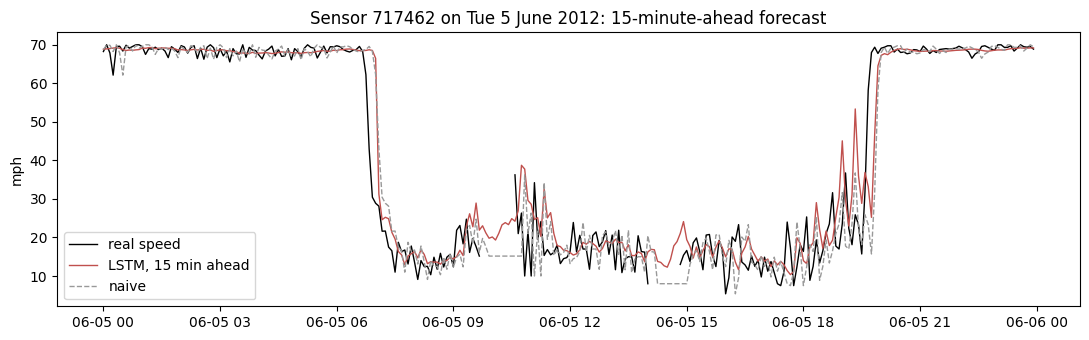

In [19]:
p_lstm, y_test = predict(lstm, loaders["test"])
results["LSTM baseline (ours)"] = horizon_report(p_lstm, y_test)
display(results["LSTM baseline (ours)"])

# Example: 15-minute-ahead forecast vs what really happened, for one full test weekday
h15 = HORIZONS["15 min"]
target_time = times[starts["test"] + 1 + h15]
day = np.flatnonzero(target_time.normalize() == pd.Timestamp("2012-06-05"))   # a Tuesday in the test split
reliable = per_sensor[per_sensor < per_sensor.median()].index                 # sensors with few missing readings
day_speed = speed.loc[target_time[day], reliable].replace(0, np.nan)
sensor = day_speed.std().idxmax()                                             # the one with the biggest jam that day
j = list(speed.columns).index(sensor)
when = target_time[day]
real = y_test[day, h15, j].numpy()
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(when, np.where(real > 0, real, np.nan), label="real speed", color="black", lw=1)
ax.plot(when, p_lstm[day, h15, j].numpy(), label="LSTM, 15 min ahead", color="#c0504d", lw=1)
ax.plot(when, p_naive[day, h15, j].numpy(), label="naive", color="#999999", lw=1, ls="--")
ax.set_title(f"Sensor {sensor} on Tue 5 June 2012: 15-minute-ahead forecast"); ax.set_ylabel("mph"); ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(ROOT, "figures", "lstm_example_sensor.png"), dpi=120)
plt.show()

**What part C shows** (LSTM trained 30 epochs on CPU, about 3.5 min per epoch; best val masked MAE 3.29)

- The LSTM beats the naive forecast at every horizon: MAE **2.40 / 3.01 / 3.62** vs 2.81 / 3.50 / 4.20 at 5 / 15 / 30 min.
- It also beats the DCRNN paper's FC-LSTM (3.44 / 3.77 at 15 / 30 min). Sharing one small LSTM across sensors
  generalises better than one big LSTM over the 207-sensor vector.
- It is still clearly behind the graph models (DCRNN 2.77 / 3.15, MTGNN 2.69 / 3.05). The gap to MTGNN is
  0.32 mph at 15 min and 0.57 at 30 min, and it grows with the horizon. That is the gap part D tries to close:
  using the road graph lets the model see congestion coming from neighbouring sensors.
- Validation MAE was still falling slowly at epoch 30 (the cap), so a longer run would gain a little more.

## D. GCN + GRU (T-GCN), trained like MTGNN

The brief's graph model is **T-GCN** (Zhao et al., IEEE T-ITS 2019): a GRU whose gates are computed with a
**graph convolution**, so each sensor's memory update also uses its neighbours on the road network.
The cell is copied from T-GCN's official PyTorch code. It is trained with the recipe of **MTGNN**,
the reference model with the lowest error (settings from MTGNN's `train.py` / `trainer.py`):

| Setting | Value (MTGNN, METR-LA) |
|---|---|
| Optimiser | Adam, learning rate 0.001, weight decay 0.0001 |
| Batch size / epochs | 64 / 100, no early stopping; keep the epoch with the lowest validation MAE |
| Gradient clipping | 5 |
| Curriculum learning | the loss starts with the 5-minute step only and adds one future step every 2,500 batches (all 12 steps after about 73 epochs) |
| Loss | masked MAE in mph |

Two changes from the T-GCN paper, both to stay on the MTGNN / DCRNN pipeline: the input has 2 features
(speed + time of day) instead of speed only, and the loss is masked MAE instead of MSE.

Training time: about 100 epochs, so run parts D and E on a GPU: **Colab** (Runtime → Change runtime type → T4 GPU) or **Kaggle**
(Settings → Accelerator → GPU T4 x2, Internet on).

### D1. Road graph

DCRNN's sensor graph: a link from sensor *i* to *j* weighted by road distance (Gaussian kernel, small weights
cut to 0). It is directed, because traffic on a highway flows one way. PyG Temporal's `adj_mat.npy` is the same
matrix as DCRNN's `adj_mx.pkl`, in the same sensor order as the speed data.

In [20]:
A_road = np.load(os.path.join(DATA_DIR, "adj_mat.npy"))                 # (207, 207)
locations = pd.read_csv(os.path.join(DATA_DIR, "graph_sensor_locations.csv"))
assert list(locations["sensor_id"].astype(str)) == [str(c) for c in speed.columns], "sensor order differs"

links = (A_road > 0) & ~np.eye(len(A_road), dtype=bool)
print(f"{links.sum():,} directed road links between sensors; "
      f"{links.sum(1).mean():.1f} per sensor on average (min {links.sum(1).min()}, max {links.sum(1).max()})")
print("symmetric:", np.allclose(A_road, A_road.T))


def tgcn_adjacency(adj):
    """T-GCN's normalised adjacency with self-loops, as in its code: D^-1/2 (A + I)^T D^-1/2, D = row sums."""
    a = torch.tensor(adj, dtype=torch.float32)
    a = a - torch.diag(torch.diag(a)) + torch.eye(len(a))     # the file already has 1 on the diagonal
    d = a.sum(1).pow(-0.5)
    return d[:, None] * a.T * d[None, :]

1,515 directed road links between sensors; 7.3 per sensor on average (min 0, max 18)
symmetric: False


### D2. Model

In [21]:
class TGCN(nn.Module):
    """GRU over time whose gates use a graph convolution over the road graph (T-GCN)."""

    def __init__(self, adj, in_dim=2, hidden=64, horizon=SEQ_OUT):
        super().__init__()
        self.hidden = hidden
        self.register_buffer("L", tgcn_adjacency(adj))
        self.gates = nn.Linear(in_dim + hidden, 2 * hidden)     # reset and update gates
        self.cand = nn.Linear(in_dim + hidden, hidden)          # candidate memory
        self.head = nn.Linear(hidden, horizon)                  # last memory -> all 12 future steps
        for lin, bias in ((self.gates, 1.0), (self.cand, 0.0)):  # T-GCN's initialisation
            nn.init.xavier_uniform_(lin.weight); nn.init.constant_(lin.bias, bias)

    def gconv(self, x, h, lin):
        """Graph convolution A [x, h] W + b: every sensor mixes in its road neighbours."""
        return lin(torch.einsum("vw,bwf->bvf", self.L, torch.cat([x, h], dim=-1)))

    def forward(self, x):                                  # x: (B, 12, N, 2)
        B, T, N, _ = x.shape
        h = x.new_zeros(B, N, self.hidden)
        for t in range(T):
            r, u = torch.sigmoid(self.gconv(x[:, t], h, self.gates)).chunk(2, dim=-1)
            c = torch.tanh(self.gconv(x[:, t], r * h, self.cand))
            h = u * h + (1 - u) * c
        return self.head(h).permute(0, 2, 1)               # (B, 12, N) z-scores


tgcn = TGCN(A_road)
print(f"T-GCN parameters: {sum(p.numel() for p in tgcn.parameters()):,}")

T-GCN parameters: 13,644


### D3. Train

epoch   1  train MAE 5.311  val MAE 11.008  (12s)  loss on 1 steps  *best
epoch   2  train MAE 4.268  val MAE 10.973  (11s)  loss on 1 steps  *best
epoch   3  train MAE 3.919  val MAE 10.952  (12s)  loss on 1 steps  *best
epoch   4  train MAE 3.699  val MAE 10.942  (12s)  loss on 1 steps  *best
epoch   5  train MAE 3.577  val MAE 10.930  (12s)  loss on 1 steps  *best
epoch   6  train MAE 3.498  val MAE 10.925  (12s)  loss on 1 steps  *best
epoch   7  train MAE 3.746  val MAE 10.308  (12s)  loss on 2 steps  *best
epoch   8  train MAE 3.674  val MAE 10.267  (12s)  loss on 2 steps  *best
epoch   9  train MAE 3.530  val MAE 10.244  (12s)  loss on 2 steps  *best
epoch  10  train MAE 3.458  val MAE 10.235  (12s)  loss on 2 steps  *best
epoch  11  train MAE 3.408  val MAE 10.227  (12s)  loss on 2 steps  *best
epoch  12  train MAE 3.365  val MAE 10.221  (12s)  loss on 2 steps  *best
epoch  13  train MAE 3.326  val MAE 10.215  (12s)  loss on 2 steps  *best
epoch  14  train MAE 3.612  val MAE 9.

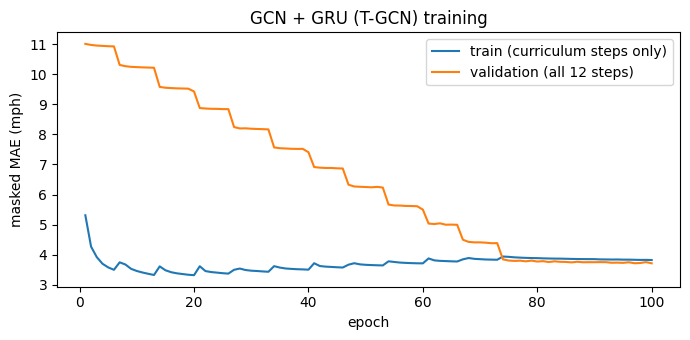

In [22]:
tgcn_history = fit(tgcn, "tgcn", **MTGNN_RECIPE)
plot_history(tgcn_history, "GCN + GRU (T-GCN) training", curriculum=True)

### D4. Test results

In [23]:
p_tgcn, _ = predict(tgcn, loaders["test"])
results["GCN + GRU, T-GCN (ours)"] = horizon_report(p_tgcn, y_test)
display(results["GCN + GRU, T-GCN (ours)"])

,MAE,RMSE,MAPE %
5 min,2.946,5.029,7.670
15 min,3.451,6.344,9.439
30 min,4.016,7.605,11.456


### D5. T-GCN v2: diffusion graph convolution + encoder–decoder

T-GCN ends up behind the time-only LSTM (D4). Three things limit it:

- **One hop, one direction.** Each gate only mixes a sensor with its direct neighbours along the road links,
  and some sensors have no links at all, so congestion further up- or downstream is invisible.
- **One linear layer for all 12 steps.** The last memory is mapped straight to 12 outputs, which is weakest
  for the far horizons, exactly where our error grows fastest.
- **Small**: one layer, 14k parameters.

Version 2 keeps T-GCN's idea (a GRU whose gates are graph convolutions) and fixes these the way DCRNN does
(Li et al., ICLR 2018; settings from its official code):

| Change | Setting |
|---|---|
| Diffusion graph convolution | random walks along the road graph **both downstream and upstream**, **2 hops** each (DCRNN's `dual_random_walk`, K = 2) |
| Encoder–decoder | 2-layer encoder reads the 12 inputs; a 2-layer decoder then predicts one step at a time, feeding each prediction back in |
| Size | 64 hidden units per layer, 2 layers (DCRNN's METR-LA setting) |
| Decoder input | its last prediction plus the **known time of day** of the step it predicts |

Data, split, masked loss and MTGNN's training recipe stay exactly as for every other model, so the scores stay
comparable. It is saved as a separate model (`tgcn_v2`): the original T-GCN above remains the brief's baseline.


In [ ]:
def random_walk(adj):
    """D^-1 A (rows sum to 1); DCRNN's calculate_random_walk_matrix."""
    a = torch.tensor(adj, dtype=torch.float32)
    d = a.sum(1, keepdim=True)
    return torch.where(d > 0, a / d.clamp(min=1e-12), torch.zeros_like(a))


class DiffusionConv(nn.Module):
    """DCRNN graph convolution: for each support P, x, P x, (2 P^2 - I) x, ... (K steps); concatenate; linear."""

    def __init__(self, c_in, c_out, n_supports=2, k=2, bias_init=0.0):
        super().__init__()
        self.k = k
        self.lin = nn.Linear(c_in * (1 + n_supports * k), c_out)
        nn.init.xavier_normal_(self.lin.weight); nn.init.constant_(self.lin.bias, bias_init)

    def forward(self, x, supports):                       # x: (B, N, C)
        out = [x]
        for P in supports:
            x0, x1 = x, torch.einsum("vw,bwc->bvc", P, x)
            out.append(x1)
            for _ in range(2, self.k + 1):                # same recurrence as DCRNN's code
                x0, x1 = x1, 2 * torch.einsum("vw,bwc->bvc", P, x1) - x0
                out.append(x1)
        return self.lin(torch.cat(out, dim=-1))


class DCGRUCell(nn.Module):
    """GRU cell whose gates are diffusion convolutions (DCRNN's DCGRUCell; same update rule as T-GCN)."""

    def __init__(self, c_in, hidden, k=2):
        super().__init__()
        self.gates = DiffusionConv(c_in + hidden, 2 * hidden, k=k, bias_init=1.0)
        self.cand = DiffusionConv(c_in + hidden, hidden, k=k)

    def forward(self, x, h, supports):
        r, u = torch.sigmoid(self.gates(torch.cat([x, h], -1), supports)).chunk(2, dim=-1)
        c = torch.tanh(self.cand(torch.cat([x, r * h], -1), supports))
        return u * h + (1 - u) * c


class TGCNv2(nn.Module):
    """T-GCN v2: 2-layer diffusion-GRU encoder-decoder over the road graph (DCRNN-style)."""

    def __init__(self, adj, in_dim=2, hidden=64, layers=2, k=2, horizon=SEQ_OUT, steps_per_day=288):
        super().__init__()
        self.hidden, self.horizon, self.steps_per_day = hidden, horizon, steps_per_day
        # downstream and upstream random walks, as DCRNN's dual_random_walk (it multiplies by their transposes)
        self.register_buffer("P_fwd", random_walk(adj).T.contiguous())
        self.register_buffer("P_bwd", random_walk(np.asarray(adj).T).T.contiguous())
        self.encoder = nn.ModuleList(DCGRUCell(in_dim if i == 0 else hidden, hidden, k) for i in range(layers))
        self.decoder = nn.ModuleList(DCGRUCell(2 if i == 0 else hidden, hidden, k) for i in range(layers))
        self.out = nn.Linear(hidden, 1)

    def _step(self, cells, x, h, supports):
        for i, cell in enumerate(cells):
            h[i] = cell(x, h[i], supports)
            x = h[i]
        return x

    def forward(self, x):                                  # x: (B, 12, N, 2) = [z-speed, time of day]
        B, T, N, _ = x.shape
        supports = (self.P_fwd, self.P_bwd)
        h = [x.new_zeros(B, N, self.hidden) for _ in self.encoder]
        for t in range(T):
            self._step(self.encoder, x[:, t], h, supports)
        tod, y, outs = x[:, -1, :, 1:], x.new_zeros(B, N, 1), []    # y starts as the GO symbol (0)
        for t in range(self.horizon):
            tod_t = torch.remainder(tod + (t + 1) / self.steps_per_day, 1.0)   # time of day being predicted
            y = self.out(self._step(self.decoder, torch.cat([y, tod_t], -1), h, supports))
            outs.append(y.squeeze(-1))
        return torch.stack(outs, dim=1)                    # (B, 12, N) z-scores


tgcn2 = TGCNv2(A_road)
print(f"T-GCN v2 parameters: {sum(p.numel() for p in tgcn2.parameters()):,} (T-GCN: 13,644)")


In [ ]:
tgcn2_history = fit(tgcn2, "tgcn_v2", **MTGNN_RECIPE)
plot_history(tgcn2_history, "T-GCN v2 (diffusion GCN + GRU encoder-decoder) training", curriculum=True)


In [ ]:
p_tgcn2, _ = predict(tgcn2, loaders["test"])
results["T-GCN v2: diffusion GCN + GRU enc-dec (ours)"] = horizon_report(p_tgcn2, y_test)
display(results["T-GCN v2: diffusion GCN + GRU enc-dec (ours)"])


## E. MTGNN re-implementation (the lowest-error model)

MTGNN (Wu et al., KDD 2020) has the lowest error among our references on METR-LA: **MAE 2.69 at 15 min,
3.05 at 30 min**. It is rebuilt here from its official code (`net.py`, `layer.py`) with the METR-LA
settings in its `train.py`, and trained with the same recipe as part D.

- **Graph learning layer**: instead of the road-distance graph, it learns its own directed graph from two
  sets of sensor embeddings (size 40) and keeps the 20 strongest links of each sensor.
- **Dilated inception layers** for time, instead of a GRU: convolutions with kernels 2, 3, 6 and 7, gated
  with tanh × sigmoid.
- **Mix-hop graph convolution**: 2 propagation steps that keep 5% of the input each time, applied along the
  learned links in both directions.
- 3 layers; 32 residual, 32 convolution, 64 skip and 128 output channels; dropout 0.3; layer norm; skip
  connections. All 12 future steps come out at once.

Differences from the original, none of which changes the model: one training run instead of the average of
10 runs; MTGNN shuffles the sensor order every 100 batches, which has no effect when the whole graph is used
at once (its `num_split=1`); its 3 residual convolutions are left out because they are never used when the
graph convolution is on.

### E1. Model

In [24]:
class GraphLearner(nn.Module):
    """Learns a sparse directed graph from sensor embeddings (MTGNN's graph_constructor)."""

    def __init__(self, n, k=20, dim=40, alpha=3.0):
        super().__init__()
        self.emb1, self.emb2 = nn.Embedding(n, dim), nn.Embedding(n, dim)
        self.lin1, self.lin2 = nn.Linear(dim, dim), nn.Linear(dim, dim)
        self.k, self.alpha = k, alpha

    def forward(self):
        m1 = torch.tanh(self.alpha * self.lin1(self.emb1.weight))
        m2 = torch.tanh(self.alpha * self.lin2(self.emb2.weight))
        adj = F.relu(torch.tanh(self.alpha * (m1 @ m2.T - m2 @ m1.T)))   # one direction per pair
        _, top = (adj + torch.rand_like(adj) * 0.01).topk(self.k, dim=1)  # small noise breaks ties
        return adj * torch.zeros_like(adj).scatter_(1, top, 1.0)          # keep the k strongest links


class MixProp(nn.Module):
    """Mix-hop propagation: h_k = a*x + (1-a)*A h_(k-1); concatenate h_0..h_depth; 1x1 convolution."""

    def __init__(self, c_in, c_out, depth=2, alpha=0.05):
        super().__init__()
        self.mlp = nn.Conv2d((depth + 1) * c_in, c_out, kernel_size=1)
        self.depth, self.alpha = depth, alpha

    def forward(self, x, adj):                             # x: (B, C, N, T)
        adj = adj + torch.eye(adj.size(0), device=x.device)
        a = adj / adj.sum(1, keepdim=True)
        h, out = x, [x]
        for _ in range(self.depth):
            h = self.alpha * x + (1 - self.alpha) * torch.einsum("ncwl,vw->ncvl", h, a)
            out.append(h)
        return self.mlp(torch.cat(out, dim=1))


class DilatedInception(nn.Module):
    """Time convolutions with kernels 2, 3, 6, 7, cut to the same length and stacked."""

    def __init__(self, c_in, c_out, dilation=1):
        super().__init__()
        self.convs = nn.ModuleList(nn.Conv2d(c_in, c_out // 4, (1, k), dilation=(1, dilation))
                                   for k in (2, 3, 6, 7))

    def forward(self, x):
        outs = [conv(x) for conv in self.convs]
        T = outs[-1].size(3)
        return torch.cat([o[..., -T:] for o in outs], dim=1)


class MTGNN(nn.Module):
    def __init__(self, n, in_dim=2, seq_len=SEQ_IN, horizon=SEQ_OUT, layers=3, kernel=7,
                 res_ch=32, conv_ch=32, skip_ch=64, end_ch=128, depth=2, dropout=0.3,
                 k=20, node_dim=40, prop_alpha=0.05, tanh_alpha=3.0):
        super().__init__()
        self.rf = layers * (kernel - 1) + 1               # receptive field: 19 steps
        self.seq_len, self.dropout = seq_len, dropout
        self.graph = GraphLearner(n, k, node_dim, tanh_alpha)
        self.start = nn.Conv2d(in_dim, res_ch, 1)
        self.skip0 = nn.Conv2d(in_dim, skip_ch, (1, self.rf))
        self.filt, self.gate, self.skips, self.gc1, self.gc2, self.norms = (nn.ModuleList() for _ in range(6))
        for j in range(1, layers + 1):
            t_out = self.rf - j * (kernel - 1)            # time steps left after layer j: 13, 7, 1
            self.filt.append(DilatedInception(res_ch, conv_ch))
            self.gate.append(DilatedInception(res_ch, conv_ch))
            self.skips.append(nn.Conv2d(conv_ch, skip_ch, (1, t_out)))
            self.gc1.append(MixProp(conv_ch, res_ch, depth, prop_alpha))
            self.gc2.append(MixProp(conv_ch, res_ch, depth, prop_alpha))
            self.norms.append(nn.LayerNorm((res_ch, n, t_out)))
        self.skipE = nn.Conv2d(res_ch, skip_ch, 1)
        self.end1 = nn.Conv2d(skip_ch, end_ch, 1)
        self.end2 = nn.Conv2d(end_ch, horizon, 1)

    def forward(self, x):                                  # x: (B, 12, N, 2)
        x = x.permute(0, 3, 2, 1)                          # (B, 2, N, 12), MTGNN's layout
        x = F.pad(x, (self.rf - self.seq_len, 0, 0, 0))    # left-pad time to the receptive field
        adj = self.graph()
        skip = self.skip0(F.dropout(x, self.dropout, self.training))
        h = self.start(x)
        for i in range(len(self.filt)):
            residual = h
            h = torch.tanh(self.filt[i](h)) * torch.sigmoid(self.gate[i](h))
            h = F.dropout(h, self.dropout, self.training)
            skip = skip + self.skips[i](h)
            h = self.gc1[i](h, adj) + self.gc2[i](h, adj.T)    # both directions of the learned graph
            h = self.norms[i](h + residual[..., -h.size(3):])
        out = F.relu(self.skipE(h) + skip)
        out = self.end2(F.relu(self.end1(out)))            # (B, 12, N, 1)
        return out.squeeze(-1)                             # (B, 12, N) z-scores


mtgnn = MTGNN(len(speed.columns))
print(f"MTGNN parameters: {sum(p.numel() for p in mtgnn.parameters()):,}")

MTGNN parameters: 402,284


### E2. Train

epoch   1  train MAE 2.632  val MAE 10.831  (163s)  loss on 1 steps  *best
epoch   2  train MAE 2.376  val MAE 10.829  (162s)  loss on 1 steps  *best
epoch   3  train MAE 2.329  val MAE 10.827  (162s)  loss on 1 steps  *best
epoch   4  train MAE 2.305  val MAE 10.826  (162s)  loss on 1 steps  *best
epoch   5  train MAE 2.288  val MAE 10.823  (162s)  loss on 1 steps  *best
epoch   6  train MAE 2.270  val MAE 10.821  (162s)  loss on 1 steps  *best
epoch   7  train MAE 2.386  val MAE 10.059  (162s)  loss on 2 steps  *best
epoch   8  train MAE 2.381  val MAE 10.051  (162s)  loss on 2 steps  *best
epoch   9  train MAE 2.355  val MAE 10.046  (162s)  loss on 2 steps  *best
epoch  10  train MAE 2.336  val MAE 10.046  (162s)  loss on 2 steps  *best
epoch  11  train MAE 2.319  val MAE 10.043  (162s)  loss on 2 steps  *best
epoch  12  train MAE 2.307  val MAE 10.046  (162s)  loss on 2 steps
epoch  13  train MAE 2.301  val MAE 10.042  (162s)  loss on 2 steps  *best
epoch  14  train MAE 2.424  val 

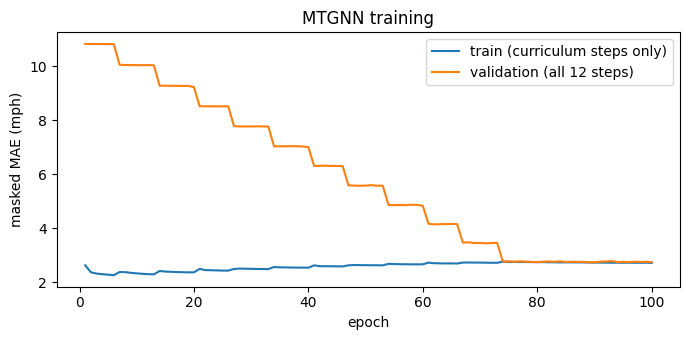

In [25]:
mtgnn_history = fit(mtgnn, "mtgnn", **MTGNN_RECIPE)
plot_history(mtgnn_history, "MTGNN training", curriculum=True)

### E3. Test results

In [26]:
p_mtgnn, _ = predict(mtgnn, loaders["test"])
results["MTGNN re-implementation (ours)"] = horizon_report(p_mtgnn, y_test)
display(results["MTGNN re-implementation (ours)"])

,MAE,RMSE,MAPE %
5 min,2.260,3.938,5.442
15 min,2.689,5.162,6.842
30 min,3.052,6.153,8.103


## F. Results (test split, masked metrics)

Paper numbers are copied from the papers' own tables (DCRNN Table 2; MTGNN multi-step table). The paper rows have
no 5-minute column because those papers report 15 / 30 / 60 minutes.

In [27]:
PAPERS = {
    "DCRNN paper: FC-LSTM": {"15 min": (3.44, 6.30), "30 min": (3.77, 7.23)},
    "DCRNN paper: DCRNN":   {"15 min": (2.77, 5.38), "30 min": (3.15, 6.45)},
    "MTGNN paper: MTGNN":   {"15 min": (2.69, 5.18), "30 min": (3.05, 6.17)},
}
rows = {name: {(h, m): v for h, (mae, rmse) in r.items() for m, v in (("MAE", mae), ("RMSE", rmse))}
        for name, r in PAPERS.items()}
for name, table in results.items():
    rows[name] = {(h, m): table.loc[h, m] for h in HORIZONS for m in ("MAE", "RMSE")}
summary = pd.DataFrame(rows).T.reindex(columns=pd.MultiIndex.from_product([list(HORIZONS), ["MAE", "RMSE"]]))
if not QUICK_CHECK:
    summary.to_csv(os.path.join(ROOT, "results.csv"))
summary.round(2)

5 min       15 min       30 min      
                                 MAE  RMSE    MAE  RMSE    MAE  RMSE
DCRNN paper: FC-LSTM             NaN   NaN   3.44  6.30   3.77  7.23
DCRNN paper: DCRNN               NaN   NaN   2.77  5.38   3.15  6.45
MTGNN paper: MTGNN               NaN   NaN   2.69  5.18   3.05  6.17
Naive: repeat last reading      2.81  4.63   3.50  6.42   4.20  8.05
LSTM baseline (ours)            2.40  4.24   3.01  5.90   3.62  7.26
GCN + GRU, T-GCN (ours)         2.95  5.03   3.45  6.34   4.02  7.60
MTGNN re-implementation (ours)  2.26  3.94   2.69  5.16   3.05  6.15

### Error at every step ahead

How the error grows from 5 to 60 minutes ahead for each of our models.

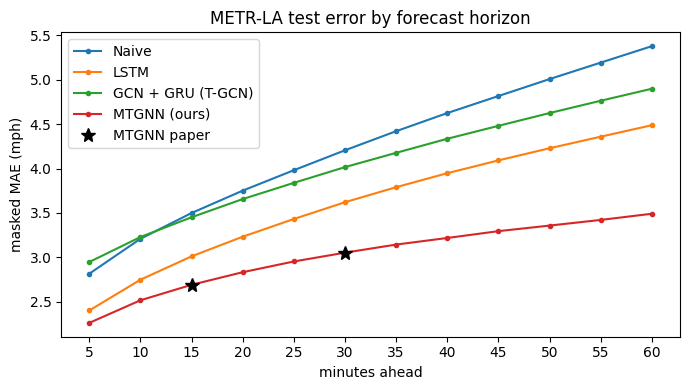

In [28]:
preds = {"Naive": None, "LSTM": p_lstm, "GCN + GRU (T-GCN)": p_tgcn, "T-GCN v2": p_tgcn2, "MTGNN (ours)": p_mtgnn}
mins = 5 * np.arange(1, SEQ_OUT + 1)
naive_all = torch.from_numpy(np.repeat(ffill[starts["test"]][:, None, :], SEQ_OUT, axis=1))
fig, ax = plt.subplots(figsize=(7, 4))
for label, p in preds.items():
    p = naive_all if p is None else p
    ax.plot(mins, [masked_mae(p[:, s], y_test[:, s]).item() for s in range(SEQ_OUT)], marker="o", ms=3, label=label)
ax.plot([15, 30], [2.69, 3.05], "k*", ms=10, label="MTGNN paper")
ax.set_xlabel("minutes ahead"); ax.set_ylabel("masked MAE (mph)"); ax.set_xticks(mins); ax.legend()
ax.set_title("METR-LA test error by forecast horizon")
plt.tight_layout()
if not QUICK_CHECK:
    plt.savefig(os.path.join(ROOT, "figures", "mae_by_horizon.png"), dpi=120)
plt.show()

### Same sensor and day as in part C

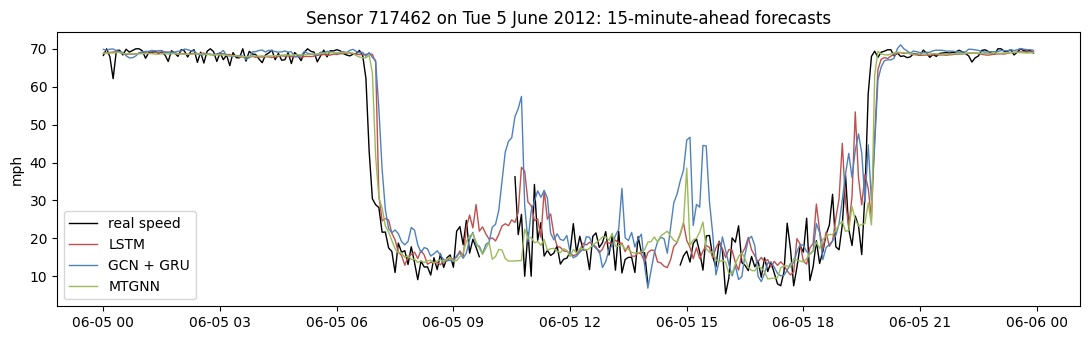

In [29]:
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(when, np.where(real > 0, real, np.nan), label="real speed", color="black", lw=1)
for label, p, color in (("LSTM", p_lstm, "#c0504d"), ("GCN + GRU", p_tgcn, "#4f81bd"), ("T-GCN v2", p_tgcn2, "#8064a2"), ("MTGNN", p_mtgnn, "#9bbb59")):
    ax.plot(when, p[day, h15, j].numpy(), label=label, color=color, lw=1)
ax.set_title(f"Sensor {sensor} on Tue 5 June 2012: 15-minute-ahead forecasts"); ax.set_ylabel("mph"); ax.legend()
plt.tight_layout()
if not QUICK_CHECK:
    plt.savefig(os.path.join(ROOT, "figures", "forecast_example_all_models.png"), dpi=120)
plt.show()

### Save the results (Colab or Kaggle)

On Colab everything above is in `MyDrive/SIREN/traffic_predictor/` on Google Drive. To put it in the GitHub repo,
upload `models/tgcn.pt`, `models/tgcn_checkpoint.pt`, `models/mtgnn.pt`, `models/mtgnn_checkpoint.pt`,
`results.csv` and the new figures to the same folders of the repo, and save this notebook with
**File → Save a copy in GitHub**.

On Kaggle, run the notebook with **Save Version → Save & Run All (Commit)**: it keeps running on Kaggle's
servers (up to 12 hours) after the browser is closed, and everything is saved in the version's **Output**
tab under `traffic_predictor/`. Download the same files from there. If a run stops before both models finish,
add its output as input (**Add Input → Your Work →** this notebook) and run again: training resumes from
the saved checkpoints.